In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp
from functions import AlgPenDisc
from functions import AlgCCS
from functions import AlgRemez
from functions import AlgCS
from functions import AlgProxPen
from functions import vf
from functions import linear
from functions import quadratic
from functions import generic_fun
from functions import vf_concave
from functions import vf_maximum_concave

In [4]:
def test(m,d,seed=0):
    np.random.seed(seed)
    res=np.zeros([4,5,d])
    k=0
    for d in np.arange(0,d):
        n=m
        I=np.eye(n)
        
        Q1=I+np.diag(np.random.rand(n))
        v=np.random.rand(n)*10-5
        def fcp(x):
            return cp.quad_form(x-v,Q1)
        def f(x):
            return (x-v).T@Q1@(x-v)
        def df(x):
            return 2*(x-v).T@Q1

        c=np.random.rand(n)*10-5
        def fcp(x):
            return c.T@x
        def f(x):
            return c.T@x
        def df(x):
            return c
        
        
        Q=np.array([np.random.rand(n) for i in range(n)])
        Q=Q.T@Q + I
        u=np.random.rand(n)*10-5
        A=np.zeros((2*n,n))
        A[:n,:n]=-np.eye(n)
        A[n:,:n]=np.eye(n)
        b=2*np.random.rand(2*n)
        X=[(linear,[A,np.ones(2*n)])]
            

        Y=[(quadratic,[I,1]) ]

        delta=np.random.rand()*0.4+0.2
        
        def gcp(x,y):
            return cp.quad_form(x,Q+np.diag(y)) +y.T@x - np.exp(sum(delta*y))
        def g(x,y):
            return x.T@(Q+np.diag(y))@(x) +y.T@x - np.exp(sum(delta*y))
        def gcps(x,y):
            cs=[ x.T@(Q+cp.diag(y))@(x) +y.T@x - cp.exp(cp.sum(delta*y))]
            return cs

        
        Y0=[np.zeros(n)]
        x0=np.zeros(n)
        
        rl=AlgProxPen(x0,Y0,fcp,gcp,g,X,Y,f=f,df=df,rho=1,concave=True,gcps=gcps,drop_cuts=True,gamma=1)
        res[0][1][k]=rl[2]
        res[1][1][k]=rl[3]
        res[2][1][k]=rl[4]
        res[3][1][k]=rl[5]

        
        rl=AlgMePa(x0,Y0,fcp,gcp,g,X,Y,concave=True,Ub=10000,gcps=gcps)
        res[0][2][k]=rl[2]
        res[1][2][k]=rl[3]
        res[2][2][k]=rl[4]
        res[3][2][k]=rl[4]
        
        rl=AlgBF(x0,Y0,fcp,gcp,g,X,Y,concave=True,gcps=gcps)
        res[0][3][k]=rl[2]
        res[1][3][k]=rl[3]
        res[2][3][k]=rl[4]
        res[3][3][k]=rl[4]
        
        rl=AlgRemez(x0,Y0,fcp,gcp,g,X,Y,concave=True,gcps=gcps)
        res[0][4][k]=rl[2]
        res[1][4][k]=rl[3]
        res[2][4][k]=rl[4]
        res[3][4][k]=rl[4]
        
        k+=1
    
    
   
    print("exp_quad_dim"+str(m)+"_seed"+str(seed))
    np.save("exp_quad_dim"+str(m)+"_seed"+str(seed), res)
    return res

def tables(res):
    print("times mean/median ProxLinDrop",np.mean(res[0][1]),np.median(res[0][1]))
    print("times mean/median CCS",np.mean(res[0][2]),np.median(res[0][2]))
    print("times mean/median CS",np.mean(res[0][3]),np.median(res[0][3]))
    print("times mean/median Remez",np.mean(res[0][4]),np.median(res[0][4]))

    print("feasibility mean/median ProxLinDrop",np.mean(res[1][1]),np.median(res[1][1]))
    print("feasibility mean/median CCS",np.mean(res[1][2]),np.median(res[1][2]))
    print("feasibility mean/median CS",np.mean(res[1][3]),np.median(res[1][3]))
    print("feasibility mean/median Remez",np.mean(res[1][4]),np.median(res[1][4]))

    print("iterations k mean/median ProxLinDrop",np.mean(res[3][1]),np.median(res[3][1]))
    print("iterations k mean/median CCS",np.mean(res[3][2]),np.median(res[3][2]))
    print("iterations k mean/median CS",np.mean(res[3][3]),np.median(res[3][3]))
    print("iterations k mean/median Remez",np.mean(res[3][4]),np.median(res[3][4]))

    print("calls vf mean/median ProxLinDrop",np.mean(res[2][1]),np.median(res[2][1]))
    print("calls vf mean/median CCS",np.mean(res[2][2]),np.median(res[2][2]))
    print("calls vf mean/median CS",np.mean(res[2][3]),np.median(res[2][3]))
    print("calls vf mean/median Remez",np.mean(res[2][4]),np.median(res[2][4]))

    plt.legend(["ProxLinDrop", "CCS","CS","Remez"])
    labels=["ProxLinDrop", "CCS","CS","Remez"]
    d=[res[0][1],res[0][2],res[0][3],res[0][4]]
    plt.boxplot(d,showfliers=False,showmeans=True, meanline=True, tick_labels=labels)
    

In [5]:
seed=np.random.randint(100000)
print(seed)
m=50
iters=50
res=test(m,iters,seed)

11711
Time 9.04319977760315
Time upper problem 8.792752981185913
Time lower problem 0.24919700622558594
Feasibility 9.630689061893016e-05
Final rho 32
Rho increases 5
Optimal value -2.021203714096232
Value function call 10
Time 158.3637411594391
Time upper problem 158.09141159057617
Time lower problem 0.27232956886291504
Feasibility 0.0007435575599843425
Optimal value -2.0309713049053837
Optimality cuts 3
Feasibility cuts 14
Value function calls 17
Time 53.41678428649902
Time upper problem 53.22148823738098
Time lower problem 0.195296049118042
Feasibility 0.0003098713450637308
Optimal value -2.0234490911453804
Value function call 9
Time 697.4652369022369
Time upper problem 696.7544400691986
Time lower problem 0.7087883949279785
Feasibility 0.000965259587617881
Optimal value -2.0241402274500917
Value function call 37
Time 16.450817346572876
Time upper problem 16.25551438331604
Time lower problem 0.19530296325683594
Feasibility 0.00045212194837849357
Final rho 64
Rho increases 6
Optimal 

times mean/median ProxLinDrop 6.3158957958221436 5.109349370002747
times mean/median CCS 109.68818286895753 88.97351324558258
times mean/median CS 22.510652008056642 19.948885917663574
times mean/median Remez 412.92858938217165 394.62624204158783
feasibility mean/median ProxLinDrop 0.00019267428721504699 0.00016680766740713622
feasibility mean/median CCS 0.0007507159593811619 0.0008419731123976218
feasibility mean/median CS 0.0005445743251258594 0.000547671427625825
feasibility mean/median Remez 0.0008984486062010688 0.000917315503137988
iterations k mean/median ProxLinDrop 9.66 9.0
iterations k mean/median CCS 18.56 17.0
iterations k mean/median CS 7.86 8.0
iterations k mean/median Remez 38.8 38.0
calls vf mean/median ProxLinDrop 11.66 11.0
calls vf mean/median CCS 18.56 17.0
calls vf mean/median CS 7.86 8.0
calls vf mean/median Remez 38.8 38.0


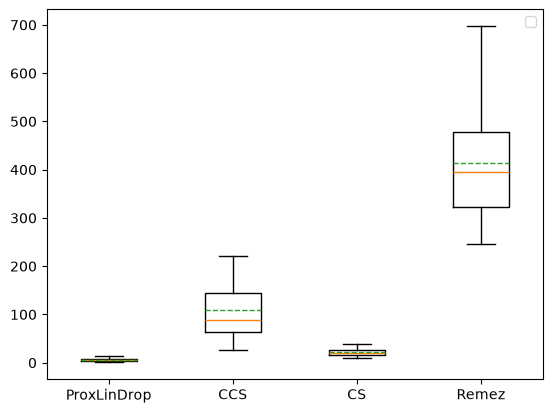

In [5]:
seed=11711
m=50
res1=np.load("exp_quad_dim"+str(m)+"_seed"+str(seed)+".npy")
tables(res1)